# 02 - Premier MLP de régression avec Keras

Ce notebook suit la démarche du tutoriel TensorFlow
[*Basic regression: Predict fuel efficiency*](https://www.tensorflow.org/tutorials/keras/regression),
appliquée au dataset de location de vélos :

1. préparer les données et les **normaliser** avec une couche `Normalization` ;
2. régression **linéaire** sur une variable, puis sur toutes ;
3. **réseau de neurones profond** (MLP) sur une variable, puis sur toutes ;
4. comparer les performances sur le jeu de test, puis sauvegarder le modèle.

La cible `cnt` est exprimée **en milliers de locations**, la fonction de perte est l'**erreur absolue moyenne (MAE)**.

In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


: 

## 1. Données

In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


In [3]:
X_train.describe().T[["mean", "std"]]

,mean,std
yr,0.505983,0.500392
holiday,0.027350,0.163242
workingday,0.680342,0.466743
temp,0.496095,0.181375
atemp,0.475421,0.161513
hum,0.628929,0.142203
windspeed,0.190853,0.078090
season_1,0.249573,0.433136
season_2,0.258120,0.437975
season_3,0.252991,0.435098


Les variables ont des échelles différentes. On ajoute donc une couche `Normalization` en tête de modèle :
elle centre-réduit chaque colonne à partir des moyennes et variances calculées sur le **train uniquement** (`adapt`).

In [4]:
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(Xtr)

first = Xtr[:1]
print("Premier exemple       :", first.round(2))
print("Premier exemple normé :", normalizer(first).numpy().round(2))

Premier exemple       : [[0.   0.   0.   0.69 0.64 0.58 0.21 0.   0.   1.   0.   0.   0.   0.
  0.   0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   1.   1.   0.   0.  ]]
Premier exemple normé : [[-1.01 -0.17 -1.46  1.05  1.01 -0.31  0.22 -0.58 -0.59  1.72 -0.56 -0.3
  -0.28 -0.3  -0.31 -0.3  -0.31  3.46 -0.32 -0.3  -0.3  -0.29 -0.32 -0.42
  -0.41 -0.41 -0.4  -0.41 -0.41  2.43  0.77 -0.72 -0.17]]


## 2. Référence naïve

Avant tout modèle, une référence : toujours prédire la moyenne du train. Un modèle utile doit faire mieux.

In [5]:
test_results = {}
test_results["référence (moyenne)"] = np.mean(np.abs(yte - ytr.mean()))
test_results

{'référence (moyenne)': np.float32(1.525586)}

## 3. Régression linéaire sur une variable (`temp`)

In [6]:
temp_train = X_train[["temp"]].to_numpy()
temp_test = X_test[["temp"]].to_numpy()

temp_normalizer = layers.Normalization(axis=None)
temp_normalizer.adapt(temp_train)

temp_model = keras.Sequential([
    keras.Input(shape=(1,)),
    temp_normalizer,
    layers.Dense(units=1),
])
temp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 3 (16.00 B)

In [7]:
temp_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss="mean_absolute_error")

history = temp_model.fit(
    temp_train, ytr,
    epochs=100,
    validation_split=0.2,  # 20 % du train sert de validation
    verbose=0,
)
pd.DataFrame(history.history).tail()

,loss,val_loss
95,1.279881,1.190477
96,1.279029,1.191165
97,1.279231,1.191064
98,1.279352,1.190412
99,1.279422,1.190018


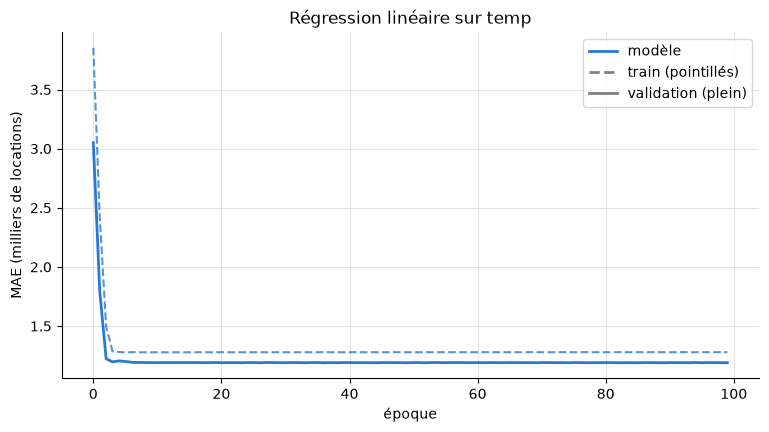

In [8]:
plot_history(history, title="Régression linéaire sur temp"); plt.show()

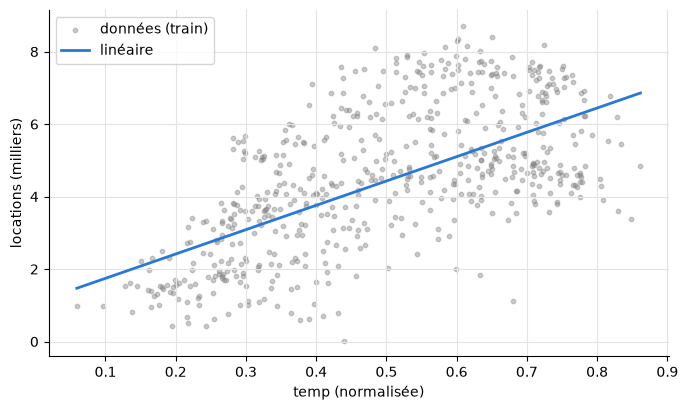

In [9]:
test_results["linéaire (temp)"] = temp_model.evaluate(temp_test, yte, verbose=0)

def plot_temp(models):
    x = np.linspace(X_train["temp"].min(), X_train["temp"].max(), 200).reshape(-1, 1)
    plt.figure(figsize=(8, 4.5))
    plt.scatter(X_train["temp"], ytr, s=10, alpha=0.4, color="gray", label="données (train)")
    for i, (name, model) in enumerate(models.items()):
        plt.plot(x, model.predict(x, verbose=0), color=PALETTE[i], label=name)
    plt.xlabel("temp (normalisée)")
    plt.ylabel("locations (milliers)")
    plt.legend()
    plt.show()

plot_temp({"linéaire": temp_model})

## 4. Régression linéaire sur toutes les variables

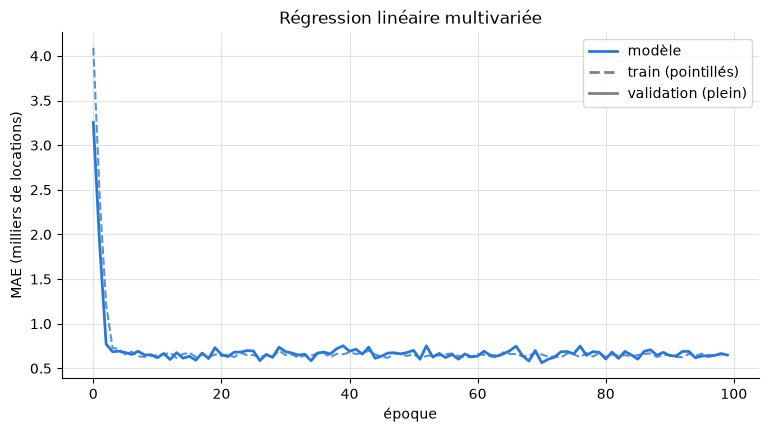

In [10]:
linear_model = keras.Sequential([
    keras.Input(shape=(n_features,)),
    normalizer,
    layers.Dense(units=1),
])
linear_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss="mean_absolute_error")

history = linear_model.fit(Xtr, ytr, epochs=100, validation_split=0.2, verbose=0)
plot_history(history, title="Régression linéaire multivariée"); plt.show()

test_results["linéaire (toutes)"] = linear_model.evaluate(Xte, yte, verbose=0)

## 5. Réseau de neurones profond (MLP)

Même pipeline, mais avec deux couches cachées de 64 neurones et une activation **ReLU** :
le modèle peut désormais apprendre des relations **non linéaires**.

In [11]:
def build_and_compile_model(norm, input_dim):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        norm,
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1),
    ])
    model.compile(loss="mean_absolute_error", optimizer=keras.optimizers.Adam(learning_rate=0.001))
    return model

### 5a. MLP sur une variable (`temp`)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,356 (17.02 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 3 (16.00 B)

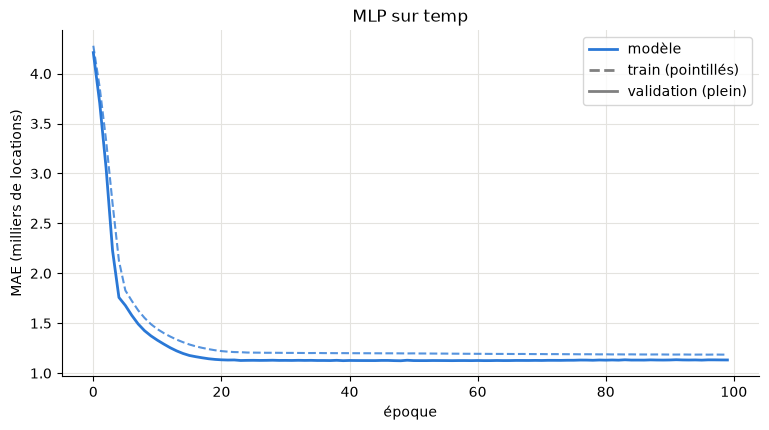

In [12]:
dnn_temp_model = build_and_compile_model(temp_normalizer, 1)
dnn_temp_model.summary()

history = dnn_temp_model.fit(temp_train, ytr, epochs=100, validation_split=0.2, verbose=0)
plot_history(history, title="MLP sur temp"); plt.show()

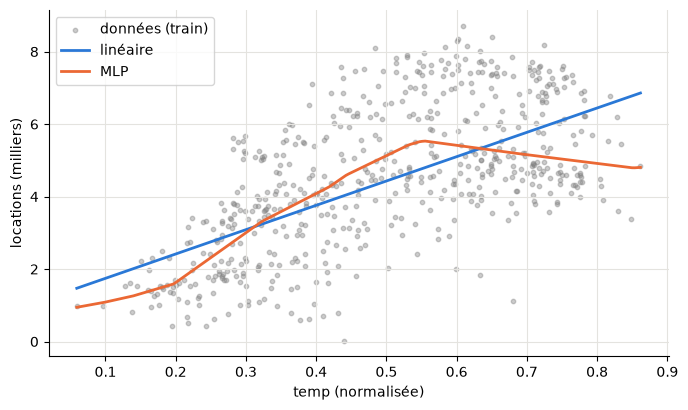

In [13]:
test_results["MLP (temp)"] = dnn_temp_model.evaluate(temp_test, yte, verbose=0)
plot_temp({"linéaire": temp_model, "MLP": dnn_temp_model})

La courbe du MLP n'est plus une droite : il capte la baisse des locations quand il fait très chaud.

### 5b. MLP sur toutes les variables

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 33)             │            67 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,468 (25.27 KB)

 Trainable params: 6,401 (25.00 KB)

 Non-trainable params: 67 (272.00 B)

Entraînement : 27.3 s


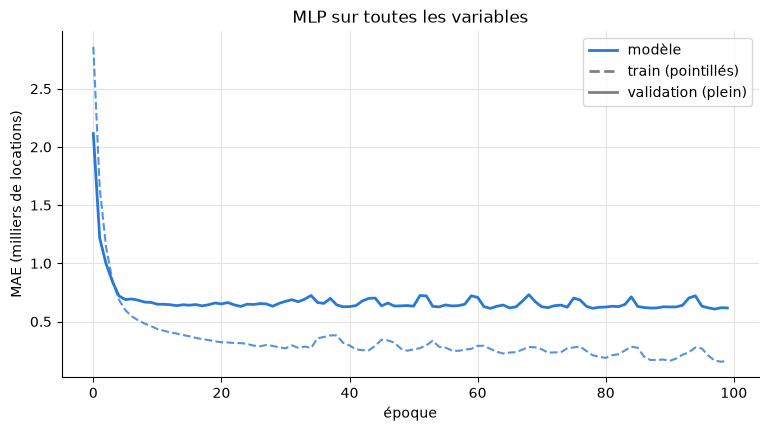

In [14]:
dnn_model = build_and_compile_model(normalizer, n_features)
dnn_model.summary()

start = time.time()
history = dnn_model.fit(Xtr, ytr, epochs=100, validation_split=0.2, verbose=0)
print(f"Entraînement : {time.time() - start:.1f} s")
plot_history(history, title="MLP sur toutes les variables"); plt.show()

In [15]:
test_results["MLP (toutes)"] = dnn_model.evaluate(Xte, yte, verbose=0)

## 6. Comparaison sur le jeu de test

In [16]:
results = pd.DataFrame(test_results, index=["MAE test (milliers)"]).T
results["MAE test (locations)"] = (results["MAE test (milliers)"] * 1000).round(0)
results

,MAE test (milliers),MAE test (locations)
référence (moyenne),1.525586,1526.0
linéaire (temp),1.185696,1186.0
linéaire (toutes),0.637126,637.0
MLP (temp),1.187347,1187.0
MLP (toutes),0.555236,555.0


## 7. Analyse des prédictions du MLP

R² sur le test : 0.816


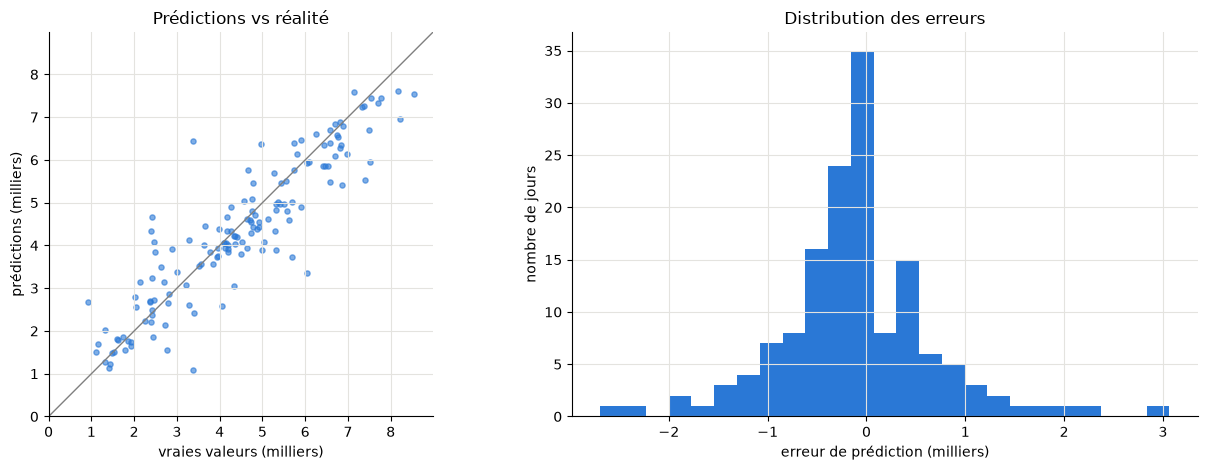

In [17]:
y_pred = dnn_model.predict(Xte, verbose=0).flatten()
r2 = 1 - np.sum((yte - y_pred) ** 2) / np.sum((yte - yte.mean()) ** 2)
print(f"R² sur le test : {r2:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.scatter(yte, y_pred, s=14, alpha=0.6)
lims = [0, max(yte.max(), y_pred.max()) * 1.05]
ax1.plot(lims, lims, color="gray", lw=1)
ax1.set(xlim=lims, ylim=lims, xlabel="vraies valeurs (milliers)", ylabel="prédictions (milliers)",
        title="Prédictions vs réalité", aspect="equal")

ax2.hist(y_pred - yte, bins=25)
ax2.set(xlabel="erreur de prédiction (milliers)", ylabel="nombre de jours", title="Distribution des erreurs")
plt.tight_layout()
plt.show()

On peut aussi superposer prédictions et réalité sur toute la période (train + test) :

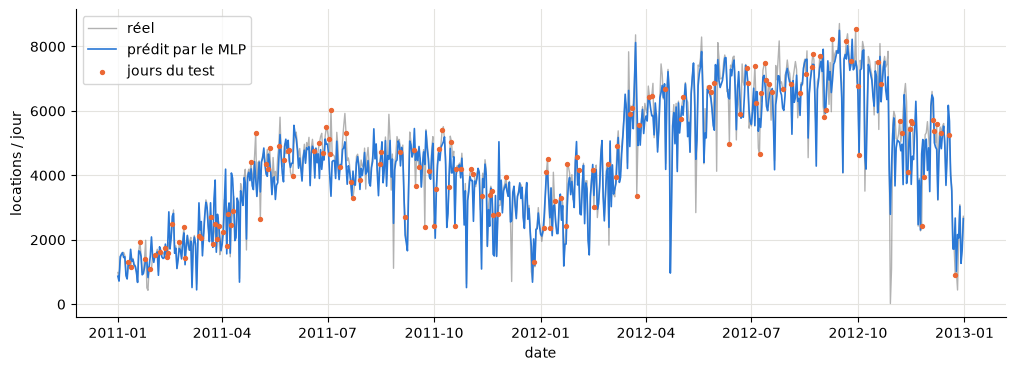

In [18]:
from velo_utils import load_raw, prepare

raw = load_raw()
X_all = prepare().drop(columns="cnt").to_numpy()
pred_all = dnn_model.predict(X_all, verbose=0).flatten() * 1000

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw["dteday"], raw["cnt"], lw=1, color="gray", alpha=0.6, label="réel")
ax.plot(raw["dteday"], pred_all, lw=1.2, color=PALETTE[0], label="prédit par le MLP")
test_dates = raw.loc[X_test.index, "dteday"]
ax.scatter(test_dates, raw.loc[X_test.index, "cnt"], s=8, color=PALETTE[1], label="jours du test", zorder=3)
ax.set(xlabel="date", ylabel="locations / jour")
ax.legend()
plt.show()

## 8. Sauvegarde et rechargement du modèle

In [19]:
from pathlib import Path

Path("modeles").mkdir(exist_ok=True)
dnn_model.save("modeles/dnn_velo.keras")

reloaded = keras.models.load_model("modeles/dnn_velo.keras")
print("MAE test du modèle rechargé :", reloaded.evaluate(Xte, yte, verbose=0))

MAE test du modèle rechargé : 0.5552364587783813


## À vous de jouer

- Changez le nombre de neurones (16, 128, 256) ou ajoutez une troisième couche cachée : la MAE de test s'améliore-t-elle ?
- Remplacez `relu` par `tanh` (l'activation utilisée dans la démo TensorFlow Playground).
- Remplacez la perte MAE par la MSE (`mean_squared_error`) : quel effet sur les grosses erreurs ?
- Retirez `yr` des variables d'entrée : de combien la performance se dégrade-t-elle ?